# Synthetic Daily Sales Dataset: University Student Canteen (2025–2026)

This notebook generates a synthetic daily sales dataset for a university student canteen (food-court level, all stalls combined) and checks that the result behaves as designed.

Each row is one operating day (Monday–Saturday). Daily meals sold are an expected level, set by the day of the week and the academic period, plus random day-to-day variation. The average meal price is drawn at random each day, and net price is meals sold × price.

**Output:** `datasets/canteen_sales_2025_2026.xlsx`

| Column | Description |
|---|---|
| `Timestamp` | Date (YYYY-MM-DD) |
| `Day_of_Week` | Monday–Saturday |
| `Weekend_Status` | `Weekend` (Saturday) or `Weekday` |
| `Academic_Period` | `Teaching`, `Mid-Semester Break` or `Semester Break` |
| `Quantity_sold` | Total meals sold that day |
| `Price_per_meal` | Average meal price (RM) |
| `Net_price` | Daily revenue: `Quantity_sold` × `Price_per_meal` (RM) |

**Sections:** 1. Configuration · 2. Operating calendar · 3. Quantity sold · 4. Price and net price · 5. Validation · 6. Export

## 1. Configuration
All adjustable parameters are defined in this one cell, so the dataset can be regenerated under different assumptions without editing the rest of the notebook.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

# Move to the repository's main folder (the folder that holds datasets/), so the dataset is saved there
# wherever the notebook is opened
from pathlib import Path
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets").is_dir()), None)
if root is not None:
    os.chdir(root)

# ---- General settings ----
SEED        = 42                        # random seed: the same seed always produces the same dataset
START, END  = "2025-01-01", "2026-12-31"   # first and last calendar date covered
TARGET_MEAN = 6440                      # desired overall mean of Quantity_sold (meals per day)

# ---- Day-to-day variation ----
NOISE_MODE  = "additive"                # "additive": same sigma on every day; "multiplicative": sigma proportional to each day's expected value
NOISE_SD    = 0.08                      # sigma as a fraction of the base level (additive) or of the expected value (multiplicative)
NOISE_CLIP  = 3                         # random draws are truncated at +/-3 sigma so no extreme outliers appear

# ---- Price and output file ----
PRICE_RANGE = (5.00, 20.00)             # lower and upper bound (RM) of the uniformly drawn average meal price
OUTPUT_FILE = "datasets/canteen_sales_2025_2026.xlsx"

# ---- Demand multipliers, relative to a teaching-week weekday (= 1.00) ----
DOW_MULT    = {"Monday": 1.00, "Tuesday": 1.00, "Wednesday": 1.00, "Thursday": 1.00, "Friday": 1.00, "Saturday": 0.50}
WEEKEND     = {"Saturday"}              # days labelled "Weekend" in Weekend_Status
PERIOD_MULT = {"Teaching": 1.00, "Mid-Semester Break": 0.85, "Semester Break": 0.60}

# ---- Academic calendar: inclusive break periods; every other date is "Teaching" ----
BREAKS = {
    "Semester Break": [("2025-04-07", "2025-04-25"), ("2025-08-25", "2025-09-19"),
                       ("2026-03-23", "2026-05-01"), ("2026-08-31", "2026-09-25")],
    "Mid-Semester Break": [("2025-06-16", "2025-06-20"), ("2025-11-10", "2025-11-14"),
                           ("2026-06-22", "2026-06-26"), ("2026-11-16", "2026-11-20")],
}
rng = np.random.default_rng(SEED)       # single random generator used for every random draw below

## 2. Operating calendar
This creates one row per operating day, skipping Sundays because the canteen is closed. Each day is then labelled with its day of the week, weekend status and academic period.

In [2]:
# All calendar dates in the period, keeping Monday-Saturday only
dates = pd.date_range(START, END, freq="D")
df = pd.DataFrame({"Timestamp": dates[dates.dayofweek != 6]})          # dayofweek 6 = Sunday
df["Day_of_Week"]    = df["Timestamp"].dt.day_name()                    # weekday name, e.g. "Monday"
df["Weekend_Status"] = np.where(df["Day_of_Week"].isin(WEEKEND), "Weekend", "Weekday")

# Every day starts as "Teaching"; dates inside each break range are then relabelled
df["Academic_Period"] = "Teaching"
for period, ranges in BREAKS.items():
    for a, b in ranges:
        df.loc[df["Timestamp"].between(a, b), "Academic_Period"] = period

# Number of operating days per year and academic period, as a quick check of the calendar
print(f"Operating days: {len(df)}")
display(df.groupby([df.Timestamp.dt.year.rename("Year"), "Academic_Period"]).size().unstack())

Operating days: 626


Academic_Period,Mid-Semester Break,Semester Break,Teaching
Year,,,
2025,10,40,263
2026,10,58,245


## 3. Quantity sold
Each day's meals sold are generated in three steps:
1. **Expected level:** base × day-of-week multiplier × academic-period multiplier. `base` is the level of a teaching-week weekday, scaled so the overall mean equals `TARGET_MEAN`.
2. **Random variation:** a standard-normal draw, truncated at ±`NOISE_CLIP`, is either added as a fixed amount (additive mode) or applied as a percentage (multiplicative mode).
3. **Rounding:** the result is rounded to a whole, non-negative number of meals.

$$E[Q_t] = \text{base}\times m_{\text{day}}(t)\times m_{\text{period}}(t)$$
$$\text{additive: } Q_t = \text{round}\big(E[Q_t] + z_t\,\sigma\,\text{base}\big) \qquad \text{multiplicative: } Q_t = \text{round}\big(E[Q_t](1 + z_t\,\sigma)\big)$$

In [3]:
# Step 1: combined multiplier for each day and the expected number of meals
mult = df["Day_of_Week"].map(DOW_MULT) * df["Academic_Period"].map(PERIOD_MULT)
base = TARGET_MEAN / mult.mean()                  # scales the base so the mean expected value equals TARGET_MEAN
expected = base * mult

# Step 2: standard-normal draws, truncated at +/-NOISE_CLIP, turned into day-to-day variation
z = np.clip(rng.normal(0, 1, len(df)), -NOISE_CLIP, NOISE_CLIP)
if NOISE_MODE == "additive":
    q = expected + z * NOISE_SD * base            # same sigma (NOISE_SD x base) on every day
else:
    q = expected * (1 + z * NOISE_SD)             # sigma proportional to the day's expected level
# Step 3: whole, non-negative meal counts
df["Quantity_sold"] = np.maximum(np.round(q), 0).astype(int)

# Report the base level, the size of the variation and the achieved mean
print(f"Noise mode: {NOISE_MODE} | base level: {base:,.0f} meals | sigma: {NOISE_SD*base:,.0f} meals" if NOISE_MODE == "additive"
      else f"Noise mode: {NOISE_MODE} | base level: {base:,.0f} meals | sigma: {NOISE_SD:.0%} of expected")
print(f"Generated mean Quantity_sold: {df['Quantity_sold'].mean():,.1f} (target {TARGET_MEAN:,})")

Noise mode: additive | base level: 7,544 meals | sigma: 604 meals
Generated mean Quantity_sold: 6,422.6 (target 6,440)


## 4. Price and net price
The average meal price is drawn uniformly within `PRICE_RANGE`, independently of the day and the academic period. Net price is the day's revenue: meals sold × average price. The columns are then put in their final order.

In [4]:
df["Price_per_meal"] = np.round(rng.uniform(*PRICE_RANGE, len(df)), 2)                # one uniform draw per day, 2 d.p.
df["Net_price"]      = np.round(df["Quantity_sold"] * df["Price_per_meal"], 2)     # daily revenue = meals sold x average price

# Final column order, sorted by date, with dates stored as YYYY-MM-DD text
COLUMNS = ["Timestamp", "Day_of_Week", "Weekend_Status", "Academic_Period", "Quantity_sold", "Price_per_meal", "Net_price"]
df = df.sort_values("Timestamp").reset_index(drop=True)[COLUMNS]
df["Timestamp"] = df["Timestamp"].dt.strftime("%Y-%m-%d")
display(df.head(10))

,Timestamp,Day_of_Week,Weekend_Status,Academic_Period,Quantity_sold,Price_per_meal,Net_price
0,2025-01-01,Wednesday,Weekday,Teaching,7728,18.43,142427.04
1,2025-01-02,Thursday,Weekday,Teaching,6916,15.07,104224.12
2,2025-01-03,Friday,Weekday,Teaching,7997,8.56,68454.32
3,2025-01-04,Saturday,Weekend,Teaching,4340,17.79,77208.60
4,2025-01-06,Monday,Weekday,Teaching,6366,10.22,65060.52
5,2025-01-07,Tuesday,Weekday,Teaching,6758,17.80,120292.40
6,2025-01-08,Wednesday,Weekday,Teaching,7621,9.48,72247.08
7,2025-01-09,Thursday,Weekday,Teaching,7353,13.85,101839.05
8,2025-01-10,Friday,Weekday,Teaching,7534,10.95,82497.30
9,2025-01-11,Saturday,Weekend,Teaching,3257,9.12,29703.84


## 5. Validation
### 5.1 Rule checks
Each requirement of the dataset is checked automatically, and the cell stops with an error if any check fails.

In [5]:
ts = pd.to_datetime(df["Timestamp"])
# Each entry maps a requirement to True (passed) or False (failed)
checks = {
    "Every Mon-Sat date 2025-2026 present, no Sundays": len(df) == (pd.date_range(START, END).dayofweek != 6).sum() and (ts.dt.dayofweek != 6).all(),
    "Sorted ascending, no duplicates": ts.is_monotonic_increasing and ts.is_unique,
    "Day_of_Week / Weekend_Status consistent with Timestamp": (ts.dt.day_name() == df.Day_of_Week).all()
        and ((df.Weekend_Status == "Weekend") == (df.Day_of_Week == "Saturday")).all(),
    "No missing values": not df.isna().any().any(),
    "Quantity_sold non-negative integer": pd.api.types.is_integer_dtype(df.Quantity_sold) and (df.Quantity_sold >= 0).all(),
    "Mean Quantity_sold within 1% of 6,440": abs(df.Quantity_sold.mean() / TARGET_MEAN - 1) < 0.01,
    "Price within RM5.00-20.00, 2 d.p.": df.Price_per_meal.between(*PRICE_RANGE).all() and np.allclose(df.Price_per_meal, df.Price_per_meal.round(2)),
    "Net_price = Quantity x Price": np.allclose(df.Net_price, (df.Quantity_sold * df.Price_per_meal).round(2)),
}
# Show the result of every check, then stop if any failed
display(pd.Series(checks, name="Passed").to_frame())
assert all(checks.values()), "A rule check failed"

,Passed
"Every Mon-Sat date 2025-2026 present, no Sundays",True
"Sorted ascending, no duplicates",True
Day_of_Week / Weekend_Status consistent with Timestamp,True
No missing values,True
Quantity_sold non-negative integer,True
"Mean Quantity_sold within 1% of 6,440",True
"Price within RM5.00-20.00, 2 d.p.",True
Net_price = Quantity x Price,True


### 5.2 Designed vs observed effects
For every combination of academic period and day of the week, this compares the observed mean (relative to the base level) with the multiplier used to generate it, and shows how spread out each group is.

In [6]:
DAYS = list(DOW_MULT)                                       # Monday-Saturday in calendar order
# Count, mean and standard deviation of meals for every period x weekday group
cell = df.groupby(["Academic_Period", "Day_of_Week"])["Quantity_sold"].agg(["count", "mean", "std"])
cell["observed_mult"] = cell["mean"] / base                  # observed mean relative to the base level
cell["designed_mult"] = [PERIOD_MULT[p] * DOW_MULT[d] for p, d in cell.index]   # multiplier used for that group
cell["std / base (%)"] = cell["std"] / base * 100            # group spread as a percentage of the base level
display(cell.reindex(DAYS, level=1).round(3))

count      mean      std  observed_mult  \
Academic_Period    Day_of_Week                                            
Mid-Semester Break Monday           4  5968.500  685.140          0.791   
                   Tuesday          4  6200.500  344.165          0.822   
                   Wednesday        4  5976.500  451.120          0.792   
                   Thursday         4  6327.750  927.778          0.839   
                   Friday           4  5952.500  312.201          0.789   
Semester Break     Monday          17  4282.471  564.685          0.568   
                   Tuesday         17  4467.235  485.655          0.592   
                   Wednesday       17  4223.118  755.105          0.560   
                   Thursday        17  4435.882  516.508          0.588   
                   Friday          17  4526.706  429.737          0.600   
                   Saturday        13  2030.077  527.497          0.269   
Teaching           Monday          83  7562.663  589.563          1.002   
                   Tuesday         83  7532.012  610.841          0.998   
                   Wednesday       84  7583.869  620.792          1.005   
                   Thursday        84  7513.810  569.866          0.996   
                   Friday          83  7593.265  574.371          1.007   
                   Saturday        91  3827.022  553.217          0.507   

                                designed_mult  std / base (%)  
Academic_Period    Day_of_Week                                 
Mid-Semester Break Monday                0.85           9.082  
                   Tuesday               0.85           4.562  
                   Wednesday             0.85           5.980  
                   Thursday              0.85          12.298  
                   Friday                0.85           4.138  
Semester Break     Monday                0.60           7.485  
                   Tuesday               0.60           6.438  
                   Wednesday             0.60          10.010  
                   Thursday              0.60           6.847  
                   Friday                0.60           5.697  
                   Saturday              0.30           6.992  
Teaching           Monday                1.00           7.815  
                   Tuesday               1.00           8.097  
                   Wednesday             1.00           8.229  
                   Thursday              1.00           7.554  
                   Friday                1.00           7.614  
                   Saturday              0.50           7.333

### 5.3 Plots
These are visual checks of the generated data: the overall distribution, weekday totals, the effects of day, academic period and weekend status, net price against quantity, and the full daily series with break periods shaded.

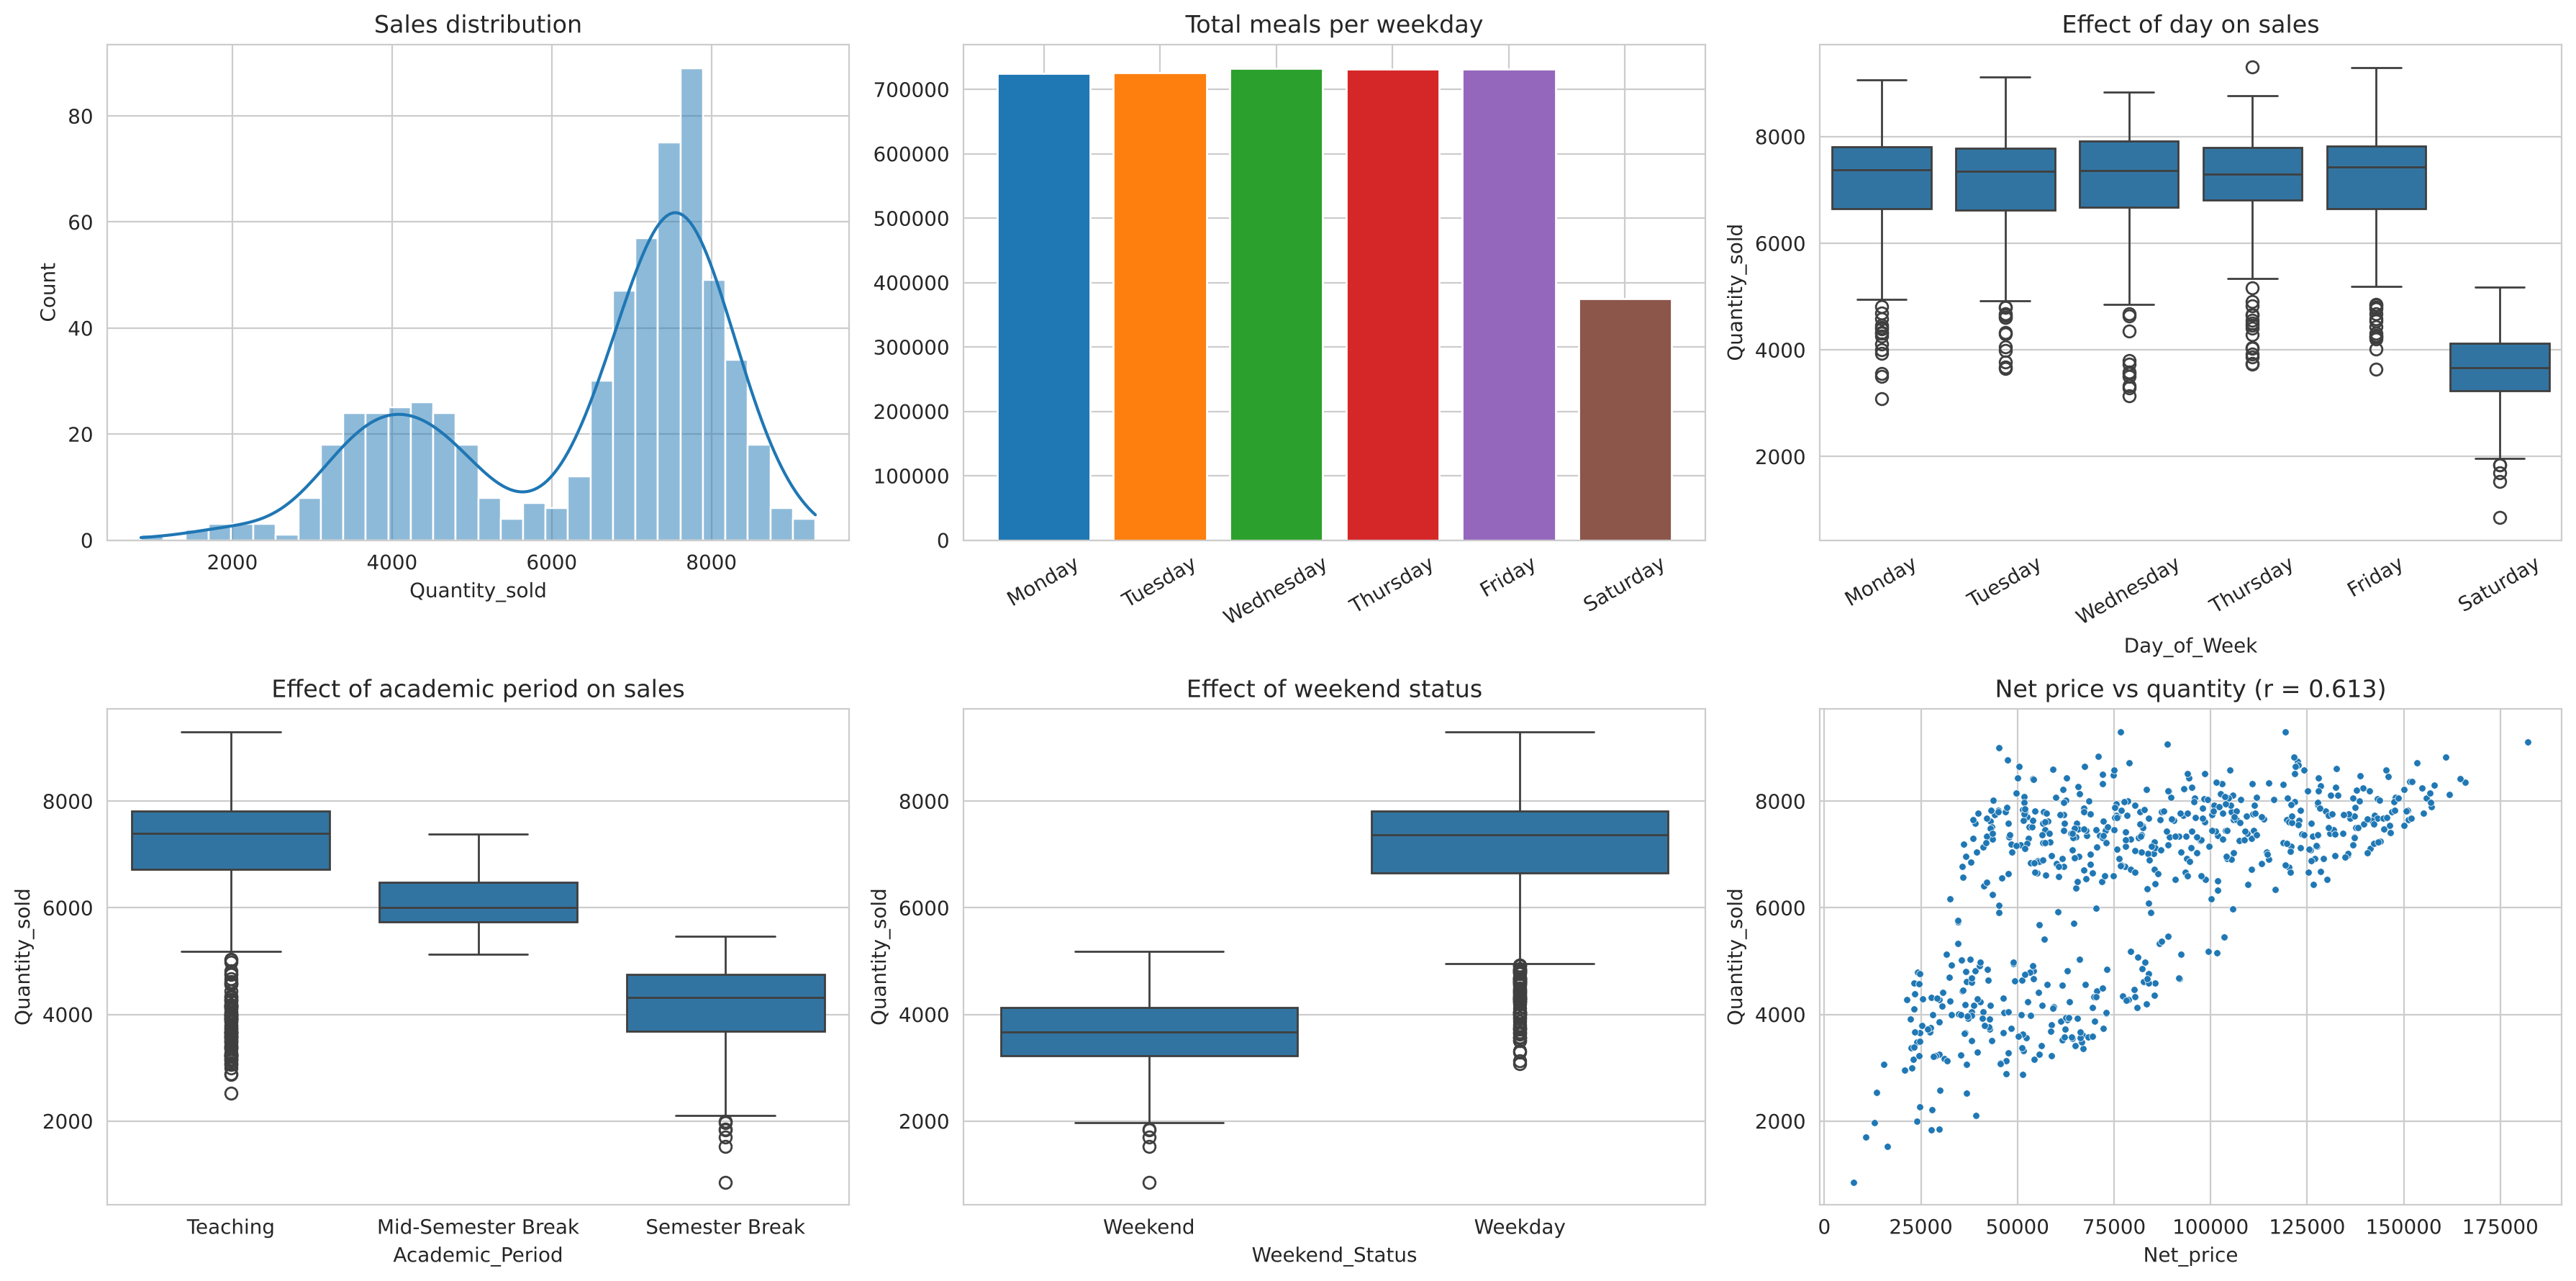

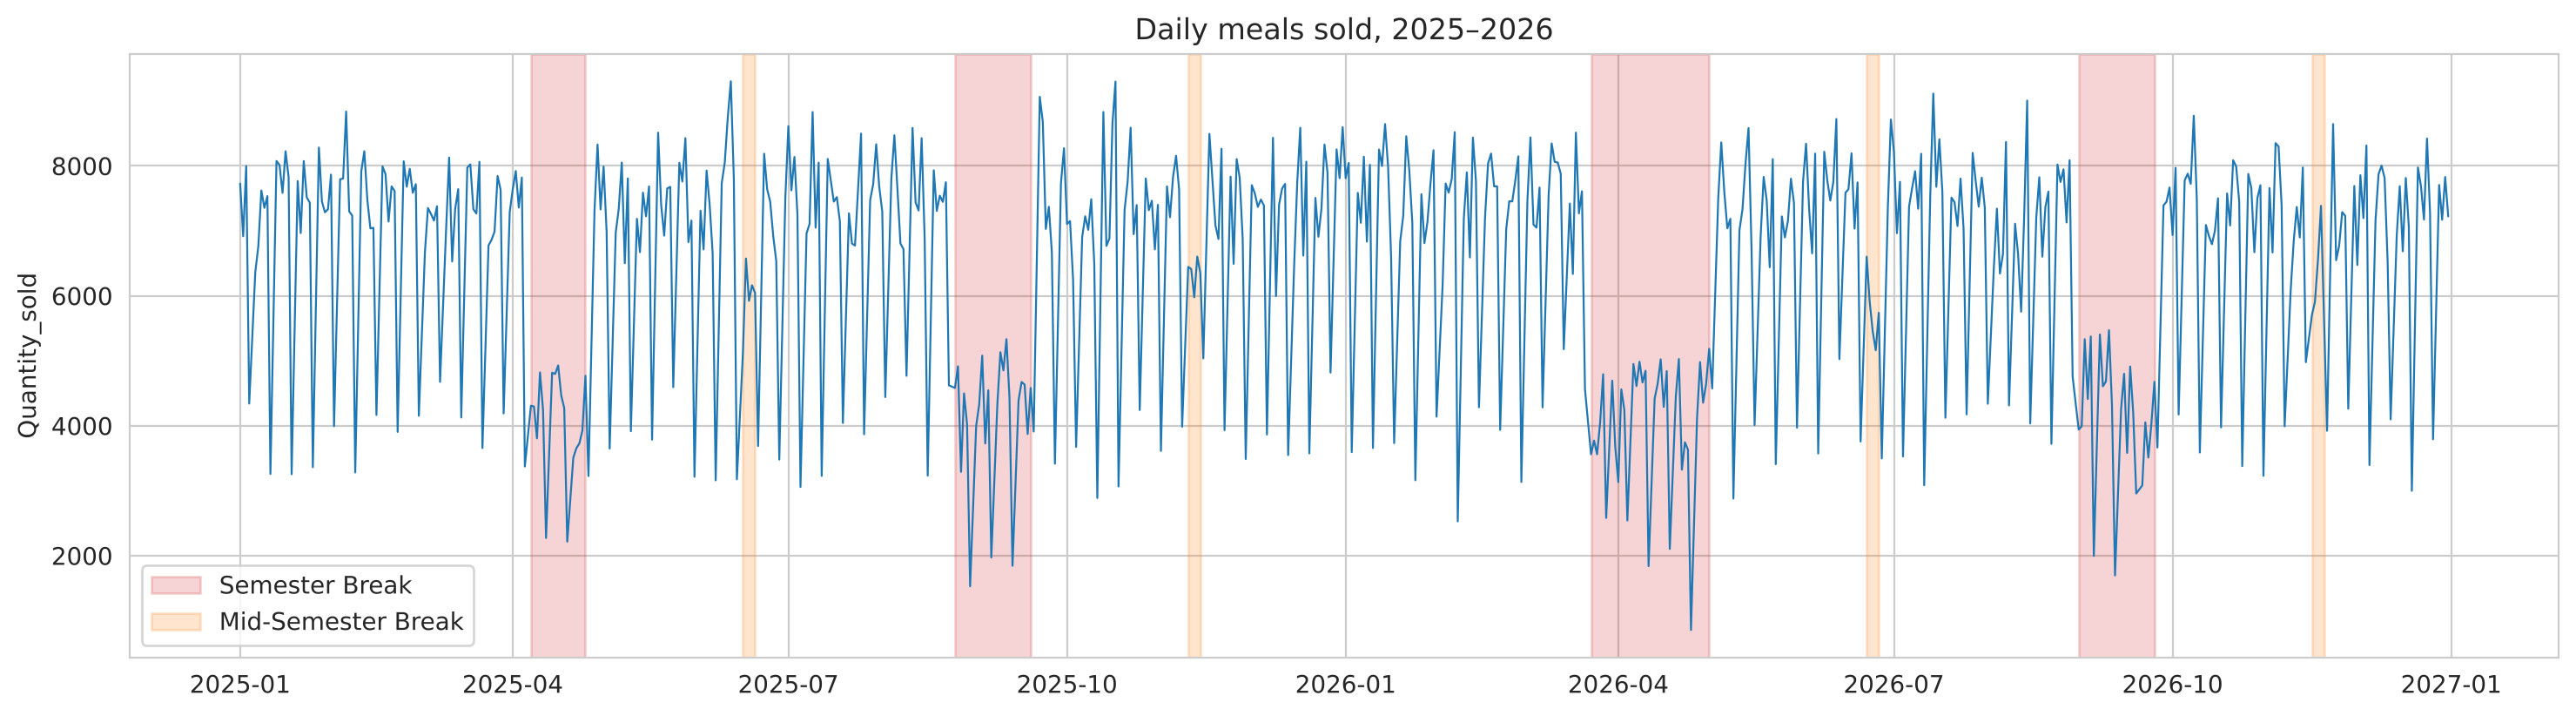

In [7]:
order_p = ["Teaching", "Mid-Semester Break", "Semester Break"]
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
# Distribution of daily meals sold
sns.histplot(df.Quantity_sold, kde=True, bins=30, ax=ax[0, 0]).set_title("Sales distribution")
# Total meals sold on each weekday over the whole period
tot = df.groupby("Day_of_Week").Quantity_sold.sum().reindex(DAYS)
ax[0, 1].bar(DAYS, tot, color=sns.color_palette("tab10", 6)); ax[0, 1].set_title("Total meals per weekday"); ax[0, 1].tick_params(axis="x", rotation=30)
# Daily meals by weekday, academic period and weekend status
sns.boxplot(data=df, x="Day_of_Week", y="Quantity_sold", order=DAYS, ax=ax[0, 2]).set_title("Effect of day on sales"); ax[0, 2].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="Academic_Period", y="Quantity_sold", order=order_p, ax=ax[1, 0]).set_title("Effect of academic period on sales")
sns.boxplot(data=df, x="Weekend_Status", y="Quantity_sold", order=["Weekend", "Weekday"], ax=ax[1, 1]).set_title("Effect of weekend status")
# Net price against quantity, with their correlation in the title
sns.scatterplot(data=df, x="Net_price", y="Quantity_sold", s=12, ax=ax[1, 2]).set_title(
    f"Net price vs quantity (r = {df[['Net_price','Quantity_sold']].corr().iloc[0,1]:.3f})")
plt.tight_layout(); plt.show()

# Full daily series with semester and mid-semester breaks shaded
fig, ax = plt.subplots(figsize=(18, 4.5))
ax.plot(ts, df.Quantity_sold, lw=0.8)
for period, col in [("Semester Break", "tab:red"), ("Mid-Semester Break", "tab:orange")]:
    for i, (a, b) in enumerate(BREAKS[period]):
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=col, alpha=.2, label=period if i == 0 else None)
ax.set(title="Daily meals sold, 2025–2026", ylabel="Quantity_sold"); ax.legend(); plt.show()

## 6. Export
This saves the dataset to Excel. The forecasting notebook reads this file.

In [8]:
# Create the output folder if needed (e.g. a fresh Colab session), then write the dataset without the pandas index column
os.makedirs(os.path.dirname(OUTPUT_FILE), exist_ok=True)
df.to_excel(OUTPUT_FILE, index=False)
print(f"Saved {OUTPUT_FILE}: {df.shape[0]} rows x {df.shape[1]} columns")

Saved datasets/canteen_sales_2025_2026.xlsx: 626 rows x 7 columns
